# PE vs Public Markets – Horizon Analysis

**Objective:** compare US private equity returns with public equities and bonds over 1 to 25 years, and show how the measurement method (naive vs mPME) changes the conclusion.

**Inputs:** `03_excel/PE_vs_Public_Markets.xlsx` (Cambridge Associates US PE Index as of 31 Mar 2026; Damodaran annual returns 1928–2025)
**Outputs:** clean CSV files in `02_data_clean`, charts in `05_outputs`

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path("..")
EXCEL = PROJECT / "03_excel" / "PE_vs_Public_Markets.xlsx"
CLEAN = PROJECT / "02_data_clean"
OUT = PROJECT / "05_outputs"
print("Excel file found:", EXCEL.exists())

Excel file found: True


## 2. Load public market returns
Annual total returns (1928–2025) for the S&P 500, US small caps, 3M T-bills, 10Y T-bonds and Baa corporate bonds, from Damodaran (NYU Stern).

In [4]:
public = pd.read_excel(EXCEL, sheet_name="Inputs_Public", header=3, usecols="A:F", nrows=98)
public.columns = ["year", "sp500", "small_cap", "tbill", "tbond_10y", "baa_corp"]
public["year"] = public["year"].astype(int)
public = public.set_index("year")
print(public.shape)
public.loc[[1928, 2008, 2025]]

(98, 5)


,sp500,small_cap,tbill,tbond_10y,baa_corp
year,,,,,
1928,0.438112,0.6215,0.0308,0.008355,0.032196
2008,-0.365523,-0.4468,0.0140,0.201013,-0.034445
2025,0.177237,0.1653,0.0421,0.077955,0.069627


## 3. Load Cambridge Associates data
US PE Index pooled horizon IRR (net of fees and carry) and the mPME returns of three public benchmarks, as of 31 Mar 2026.

In [5]:
ca = pd.read_excel(EXCEL, sheet_name="Inputs_CA", header=3, usecols="B:H", nrows=4)
ca.index = ["pe_index", "mpme_acwi", "mpme_russell3000", "mpme_russell2000"]
ca.columns = [1, 3, 5, 10, 15, 20, 25]
ca

,1,3,5,10,15,20,25
pe_index,0.0642,0.0735,0.0915,0.1508,0.1452,0.1288,0.1276
mpme_acwi,0.2075,0.1714,0.1073,0.1225,0.1012,0.0866,0.0872
mpme_russell3000,0.1838,0.1796,0.1143,0.1395,0.1296,0.1060,0.1003
mpme_russell2000,0.2581,0.1304,0.0480,0.1006,0.0925,0.0826,0.0903


## 4. Export clean data
Save both datasets as CSV so that later notebooks do not depend on the Excel file.

In [6]:
public.to_csv(CLEAN / "public_annual_returns_1928_2025.csv")
ca.to_csv(CLEAN / "ca_uspe_horizon_returns_2026q1.csv")
print("Saved:", [p.name for p in CLEAN.glob("*.csv")])

Saved: ['public_annual_returns_1928_2025.csv', 'ca_uspe_horizon_returns_2026q1.csv']


## 5. Annualised returns by horizon
Geometric annualised return (CAGR) of each public asset over the last 1, 3, 5, 10, 15, 20 and 25 years to 2025:

$$CAGR = \left(\prod_{t=1}^{n}(1+r_t)\right)^{1/n} - 1$$

Cross-check: results must match the `Horizon_Analysis` sheet in Excel.

In [7]:
def cagr(returns):
    return (1 + returns).prod() ** (1 / len(returns)) - 1

horizons = [1, 3, 5, 10, 15, 20, 25]
end_year = 2025

horizon = pd.DataFrame({
    h: public.loc[end_year - h + 1 : end_year].apply(cagr) for h in horizons
})
horizon.loc["pe_index"] = ca.loc["pe_index"]
horizon = horizon.loc[["pe_index", "sp500", "small_cap", "tbond_10y", "baa_corp", "tbill"]]
(horizon * 100).round(2)

,1,3,5,10,15,20,25
pe_index,6.42,7.35,9.15,15.08,14.52,12.88,12.76
sp500,17.72,22.83,14.31,14.68,13.94,10.90,8.74
small_cap,16.53,10.04,4.69,7.86,7.65,6.27,9.65
tbond_10y,7.80,3.27,-2.86,0.89,1.93,2.78,3.34
baa_corp,6.96,5.77,0.26,4.29,4.79,5.32,6.18
tbill,4.21,4.89,3.34,2.23,1.50,1.67,1.77


## 6. PE excess return: naive vs mPME
- **Naive:** PE IRR minus S&P 500 CAGR. Mixes a money-weighted and a time-weighted return.
- **mPME:** Cambridge Associates invests the same cash flows, at the same dates, in the Russell 3000. Like-for-like comparison.

In [8]:
gap = pd.DataFrame({
    "Naive: PE vs S&P 500": (horizon.loc["pe_index"] - horizon.loc["sp500"]) * 10_000,
    "mPME: PE vs Russell 3000": (ca.loc["pe_index"] - ca.loc["mpme_russell3000"]) * 10_000,
}).round(0)
gap

,Naive: PE vs S&P 500,mPME: PE vs Russell 3000
1,-1130.0,-1196.0
3,-1548.0,-1061.0
5,-516.0,-228.0
10,40.0,113.0
15,58.0,156.0
20,198.0,228.0
25,402.0,273.0


## 7. Chart 1 – Annualised returns by horizon

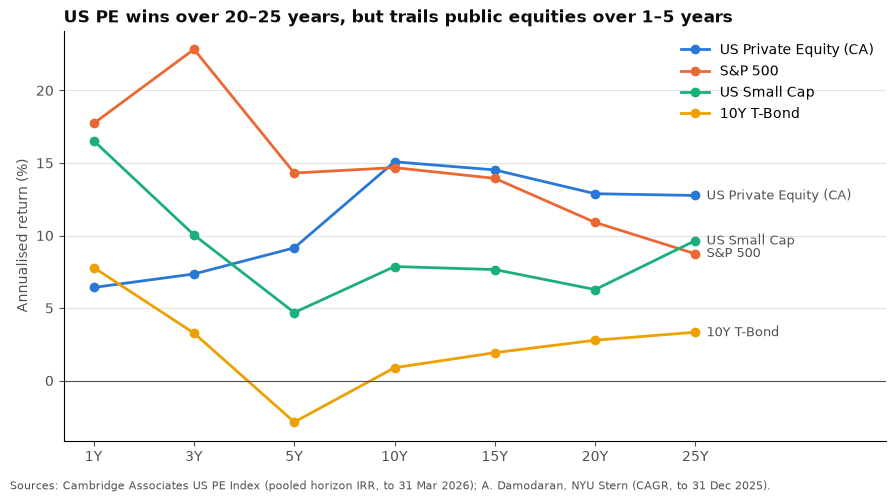

In [9]:
plt.rcParams.update({"font.family": "sans-serif", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

series = {"pe_index": ("US Private Equity (CA)", "#2a78d6"),
          "sp500": ("S&P 500", "#eb6834"),
          "small_cap": ("US Small Cap", "#1baf7a"),
          "tbond_10y": ("10Y T-Bond", "#eda100")}
labels = [f"{h}Y" for h in horizons]
x = np.arange(len(horizons))

fig, ax = plt.subplots(figsize=(9, 5))
for key, (name, color) in series.items():
    y = horizon.loc[key].values * 100
    ax.plot(x, y, color=color, lw=2, marker="o", ms=6, label=name)
    ax.annotate(name, (x[-1], y[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=MUTED, fontsize=9)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(x, labels)
ax.set_xlim(-0.3, len(x) + 0.9)
ax.set_ylabel("Annualised return (%)", color=MUTED)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="upper right")
ax.set_title("US PE wins over 20–25 years, but trails public equities over 1–5 years",
             loc="left", fontsize=12, color=INK, fontweight="bold")
fig.text(0.01, 0.01, "Sources: Cambridge Associates US PE Index (pooled horizon IRR, to 31 Mar 2026); "
         "A. Damodaran, NYU Stern (CAGR, to 31 Dec 2025).", fontsize=8, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(OUT / "01_horizon_returns.png", dpi=200)
plt.show()

## 8. Chart 2 – Naive vs mPME comparison

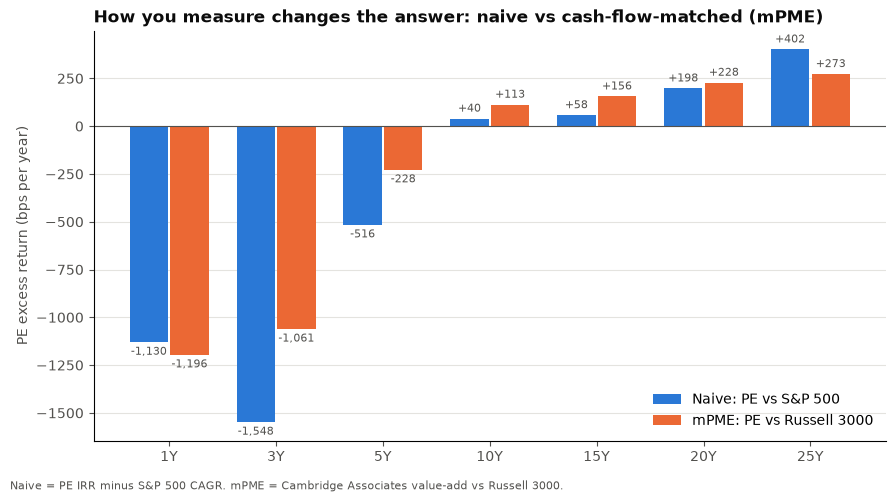

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
w = 0.38
for i, (col, color) in enumerate(zip(gap.columns, ["#2a78d6", "#eb6834"])):
    vals = gap[col].values
    ax.bar(x + (i - 0.5) * w, vals, width=w - 0.02, color=color, label=col)
    for xi, v in zip(x + (i - 0.5) * w, vals):
        ax.annotate(f"{v:+,.0f}", (xi, v), xytext=(0, 3 if v >= 0 else -3),
                    textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=8, color=MUTED)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(x, labels)
ax.set_ylabel("PE excess return (bps per year)", color=MUTED)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="lower right")
ax.set_title("How you measure changes the answer: naive vs cash-flow-matched (mPME)",
             loc="left", fontsize=12, color=INK, fontweight="bold")
fig.text(0.01, 0.01, "Naive = PE IRR minus S&P 500 CAGR. mPME = Cambridge Associates value-add vs Russell 3000.",
         fontsize=8, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(OUT / "02_naive_vs_mpme.png", dpi=200)
plt.show()

## Key takeaways
1. Over 20–25 years, US PE outperformed the S&P 500 (+198 to +402 bps per year, naive).
2. Over 1–5 years, PE trailed public equities by a wide margin, driven by the strong rally in US large caps since 2023.
3. The measurement method matters, in both directions: over 25 years the naive gap (+402 bps) shrinks to +273 bps with the cash-flow-matched mPME, while over 10–20 years the mPME is more favourable to PE (+113 vs +40 bps over 10 years). Part of the difference also comes from the benchmark (S&P 500 vs Russell 3000).
4. Bonds lagged PE over every horizon except 1 year; 10Y T-bonds returned -2.86% per year over 5 years after the 2022 rate shock.